# Predicting Overall Survival in Breast Cancer Patients Using Cox Proportional Hazards Regression

## Objective

Build a Cox proportional hazards model that predicts overall survival from five clinical variables known at diagnosis, check that every modelling choice is supported by the data or by published research, measure how well the model predicts survival for patients it has never seen, and turn it into a tool that gives an individual patient's predicted survival.

---

## Notebook Outline

0. Setup
1. Data and Outcome
2. Missing Data
3. Train/Test Split and Validation Plan
4. Choosing the Predictors
5. Starting Model and the Proportional Hazards Check
6. Fixing the Violations: ER Status and Grade as Strata
7. How the Model Is Scored
8. The Shape of Each Continuous Predictor
9. How Flexible the Splines Should Be
10. Final Model
11. Re-checking Proportional Hazards
12. Test Set
13. How Stable Is the Test Score?
14. What the Model Says About Each Predictor
15. How Far Ahead Can the Model Predict?
16. Patient Prediction Form
17. Conclusions and Limitations
18. References

## 0. Setup

In [1]:
!pip install lifelines
from lifelines import CoxPHFitter #implementation of the Cox model in lifelines
from lifelines.statistics import proportional_hazard_test #Schoenfeld residual test for proportional hazards
from lifelines.utils import concordance_index #used to score the model (C-index)
import pandas as pd #used for data set
import numpy as np #used for math functions
import matplotlib.pyplot as plt #used for visuals
from sklearn.model_selection import train_test_split, KFold #used to split data and for cross validation
import warnings
warnings.filterwarnings("ignore", message="DataFrame Index is not unique") #harmless lifelines warning with strata

## 1. Data and Outcome

The data is the METABRIC breast cancer cohort (Curtis et al., 2012), downloaded from cBioPortal (Cerami et al., 2012; Gao et al., 2013). The tumours were collected between 1977 and 2005 from five centres in the UK and Canada (Mukherjee et al., 2018).

**Outcome: overall survival.** A patient has an event when she dies from any cause; living patients are censored at their last follow-up.

Why overall survival instead of breast-cancer-specific survival:

- **It answers the question the prediction tool asks**: how likely a patient is to be alive at a given time.
- **It does not depend on the recorded cause of death.** Cancer-specific survival depends on cause of death being classified correctly, and misclassification biases it (Sarfati et al., 2010).
- **It avoids treating other deaths as censored.** A cancer-specific Cox model censors deaths from other causes, which assumes those patients would have had the same risk of dying from breast cancer as patients still being followed. That assumption is questionable, particularly in older patients who often die of other diseases (Frontiers in Oncology, 2024).

The five candidate predictors are the clinical variables known at diagnosis: age, tumour size, number of positive lymph nodes, histologic grade and ER status. Section 4 explains why each is included.

In [2]:
# Load the METABRIC clinical data from the GitHub repo
url = "https://raw.githubusercontent.com/abdulksidani-png/breast-cancer-overall-survival-cox/refs/heads/main/data/brca_metabric_clinical_data.tsv"
data = pd.read_csv(url, sep='\t')

# Map survival status to 0 and 1 (overall survival: death from any cause counts as an event)
data["Patient's Vital Status"] = data["Patient's Vital Status"].map({
    'Living': 0,
    'Died of Disease': 1,
    'Died of Other Causes': 1
})

surv_time = 'Overall Survival (Months)'
surv_status = "Patient's Vital Status"

# Select relevant columns
data_cols = data[['Age at Diagnosis',
                  'Tumor Size',
                  'Lymph nodes examined positive',
                  'Neoplasm Histologic Grade',
                  'ER status measured by IHC',
                  surv_time,
                  surv_status
                 ]].copy()

# Convert numerical columns to numbers
for col in ['Age at Diagnosis', 'Tumor Size',
            'Lymph nodes examined positive',
            'Neoplasm Histologic Grade',
            surv_time]:
    data_cols[col] = pd.to_numeric(data_cols[col], errors='coerce')

print(f"{len(data_cols)} patients in the file")

2509 patients in the file


> **Result**
>
> The file holds **2,509 patients**. The next section looks at how many of them have complete information.

## 2. Missing Data

Patients missing a predictor or the outcome cannot be used directly. The simplest approach, complete-case analysis, keeps only patients with every value present.

Complete-case analysis gives unbiased regression results when whether a patient is complete does not depend on her outcome, after taking the predictors into account (Hughes et al., 2019). Below we count the missing values and check whether patients with a missing predictor have different survival from complete patients. (This check does not adjust for the predictors, so it is a simplified version of that condition.)

In [3]:
# How much data is missing in each column?
print(data_cols.isna().sum())

# Patients without survival data can't be used at all, so look only at the ones with an outcome
has_outcome = data_cols.dropna(subset=[surv_time, surv_status]).copy()
has_outcome['complete'] = has_outcome.notna().all(axis=1).astype(int)
print(f"\nPatients with an outcome: {len(has_outcome)}, complete on all predictors: {has_outcome['complete'].sum()}")

# Is missing a predictor related to the outcome? If yes, dropping those patients could bias the model
missing_check = CoxPHFitter()
missing_check.fit(has_outcome[[surv_time, surv_status, 'complete']],
                  duration_col=surv_time, event_col=surv_status)
print(missing_check.summary[['exp(coef)', 'p']])

Age at Diagnosis                  11
Tumor Size                       149
Lymph nodes examined positive    266
Neoplasm Histologic Grade        121
ER status measured by IHC         83
Overall Survival (Months)        528
Patient's Vital Status           529
dtype: int64

Patients with an outcome: 1980, complete on all predictors: 1793
           exp(coef)         p
covariate                     
complete    1.049077  0.629221


> **Result**
>
> - **528 patients have no survival time**, so they cannot be used in a survival model at all.
> - **Of the 1,980 patients with an outcome, 1,793 are complete** on all five predictors. The largest gap is lymph nodes (266 missing).
> - **Survival does not differ** between complete and incomplete patients (HR 1.05, p = 0.63).
>
> This supports complete-case analysis. Multiple imputation would keep the 187 incomplete patients and gain some statistical power, which is listed as a limitation in Section 17.

In [4]:
# Remove missing values (complete-case analysis, see the check above)
data_cols = data_cols.dropna()

# Convert ER status into 0 and 1 (Negative and Positive, respectively)
data_cols = pd.get_dummies(data_cols, columns=['ER status measured by IHC'],
                           drop_first=True, dtype=int)

print(f"{len(data_cols)} patients, {int(data_cols[surv_status].sum())} deaths "
      f"({data_cols[surv_status].mean():.1%})")

1793 patients, 1029 deaths (57.4%)


> **Result**
>
> After removing incomplete patients: **1,793 patients and 1,029 deaths (57.4%)**.

## 3. Train/Test Split and Validation Plan

A model scored on the same patients it was fitted on looks better than it really is. The TRIPOD reporting guideline therefore treats internal validation, such as cross-validation, as a necessary part of building a prediction model (Collins et al., 2015).

The plan:

1. **Split the data 80/20** into training and test sets, stratified on the event so both sets have the same death rate.
2. **Make every modelling decision using the training set only**, with 5-fold cross-validation.
3. **Score the test set once**, at the very end.

A single random split is a weak form of validation on its own: with a large dataset, the two parts differ only by chance (Debray et al., 2023). So **cross-validation is the main performance estimate**, the test set is a final check, and Section 13 measures how much the test score depends on the random split.

We also check that there are enough deaths for the number of model terms. A Cox model needs at least about 10 events per variable (Peduzzi et al., 1995).

In [5]:
# Shuffle and split the data 80/20 into training and test sets
# (stratified on the event so both sets have the same death rate)
train_df, test_df = train_test_split(data_cols, test_size=0.2, shuffle=True,
                                     random_state=42, stratify=data_cols[surv_status])
print(f"Train: {len(train_df)} patients, {int(train_df[surv_status].sum())} deaths")
print(f"Test:  {len(test_df)} patients, {int(test_df[surv_status].sum())} deaths")

# Events per variable: enough deaths for the number of model terms? (Peduzzi et al. 1995: at least 10)
max_terms = 11  # the most flexible model compared below (5 age + 3 node spline terms, size, ER, grade)
print(f"Events per variable (worst case): {train_df[surv_status].sum() / max_terms:.0f}")

Train: 1434 patients, 823 deaths
Test:  359 patients, 206 deaths
Events per variable (worst case): 75


> **Result**
>
> - **Training set:** 1,434 patients and 823 deaths.
> - **Test set:** 359 patients and 206 deaths.
> - **Events per variable:** even the most flexible model compared below (11 terms) has about **75 deaths per term**, far above the minimum of 10.

## 4. Choosing the Predictors

The predictors were chosen from the literature before looking at any results:

- **Tumour size, lymph node status and histologic grade** are the three main prognostic factors used in routine practice for early breast cancer (Rakha et al., 2010). Together they make up the Nottingham Prognostic Index.
- **ER status** is the main hormone-receptor biomarker, and the risk of death differs strongly between ER-positive and ER-negative cancers over time (Anderson et al., 2006).
- **Age** is the strongest driver of death from any cause, which matters because the outcome is overall survival.

**Why univariable p-values are not used to choose predictors.** Dropping predictors that are not significant on their own is a common but inappropriate practice. A predictor can look unimportant alone and turn out to be important once confounding is accounted for (Sun et al., 1996). The univariable models below are therefore descriptive only.

In [6]:
# Univariable Cox models on the training set: each predictor on its own
# (descriptive only, NOT used to choose predictors; see the note above)
predictors = ['Age at Diagnosis', 'Tumor Size', 'Lymph nodes examined positive',
              'Neoplasm Histologic Grade', 'ER status measured by IHC_Positve']
univariable = []
for var in predictors:
    model = CoxPHFitter()
    model.fit(train_df[[var, surv_time, surv_status]], duration_col=surv_time, event_col=surv_status)
    row = model.summary.loc[var]
    univariable.append({'variable': var, 'HR': row['exp(coef)'],
                        'HR lower 95%': row['exp(coef) lower 95%'],
                        'HR upper 95%': row['exp(coef) upper 95%'], 'p': row['p']})
print(pd.DataFrame(univariable).round(4).to_string(index=False))

                         variable     HR  HR lower 95%  HR upper 95%      p
                 Age at Diagnosis 1.0367        1.0305        1.0429 0.0000
                       Tumor Size 1.0140        1.0109        1.0172 0.0000
    Lymph nodes examined positive 1.0909        1.0759        1.1061 0.0000
        Neoplasm Histologic Grade 1.2238        1.0969        1.3652 0.0003
ER status measured by IHC_Positve 0.8763        0.7439        1.0323 0.1141


> **Result**
>
> Age, tumour size, lymph nodes and grade are all significant on their own.
>
> **ER status is not significant on its own** (HR 0.88, p = 0.11), but it is highly significant in the multivariable model in Section 5 (HR 0.72, p < 0.005). Screening on univariable p-values would have wrongly dropped it, which is the exact problem Sun et al. (1996) describe.

## 5. Starting Model and the Proportional Hazards Check

We start with all five predictors as straight-line (linear) terms.

The Cox model assumes **proportional hazards**: each predictor multiplies the risk of death by the same amount throughout follow-up. We test this with the Schoenfeld residual test (Grambsch & Therneau, 1994), on two time scales (rank and Kaplan-Meier). A p-value below 0.05 is evidence that a predictor's effect changes over time.

With over 1,000 patients, the test can flag small departures. So we also look at the residual plots for the final model in Section 11.

In [7]:
# Starting model: all five predictors as plain straight-line (linear) terms
baseline = CoxPHFitter()
baseline.fit(train_df, duration_col=surv_time, event_col=surv_status)
baseline.print_summary()

# Proportional hazards test (Grambsch & Therneau 1994) on two time scales
ph_baseline = pd.concat([proportional_hazard_test(baseline, train_df, time_transform=t).summary['p'].rename(t)
                         for t in ['rank', 'km']], axis=1)
print(ph_baseline.round(4))

<lifelines.CoxPHFitter: fitted with 1434 total observations, 611 right-censored observations>
             duration col = 'Overall Survival (Months)'
                event col = 'Patient's Vital Status'
      baseline estimation = breslow
   number of observations = 1434
number of events observed = 823
   partial log-likelihood = -5251.49
         time fit was run = 2026-11-14 22:41:44 UTC

---
                                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                          
Age at Diagnosis                   0.04      1.04      0.00            0.03            0.05                1.03                1.05
Tumor Size                         0.01      1.01      0.00            0.01            0.01                1.01                1.01
Lymph nodes examined positive      0.08      1.08      0.01            0.06            0.09                1.06                1.10
Neoplasm Histologic Grade          0.14      1.15      0.06            0.02            0.26                1.02                1.29
ER status measured by IHC_Positve -0.33      0.72      0.09           -0.51           -0.15                0.60                0.86

                                   cmp to     z      p  -log2(p)
covariate                                                       
Age at Diagnosis                     0.00 12.59 <0.005    118.39
Tumor Size                           0.00  4.79 <0.005     19.22
Lymph nodes examined positive        0.00  9.81 <0.005     73.09
Neoplasm Histologic Grade            0.00  2.32   0.02      5.61
ER status measured by IHC_Positve    0.00 -3.52 <0.005     11.17
---
Concordance = 0.67
Partial AIC = 10512.98
log-likelihood ratio test = 302.14 on 5 df
-log2(p) of ll-ratio test = 207.49

                                     rank      km
Age at Diagnosis                   0.0000  0.0000
ER status measured by IHC_Positve  0.0000  0.0000
Lymph nodes examined positive      0.2287  0.3394
Neoplasm Histologic Grade          0.0022  0.0033
Tumor Size                         0.9389  0.8647


> **Result**
>
> Three predictors fail the proportional hazards test on both time scales:
>
> | Predictor | Rank p | KM p |
> |---|---|---|
> | Age at diagnosis | < 0.0001 | < 0.0001 |
> | ER status | < 0.0001 | < 0.0001 |
> | Histologic grade | 0.0022 | 0.0033 |
> | Lymph nodes | 0.23 | 0.34 |
> | Tumour size | 0.94 | 0.86 |
>
> These failures match the literature. The effects of age, histologic grade and ER status on breast cancer survival are documented to change over time (Frontiers in Oncology, 2024). For ER, the hazard of death for ER-negative and ER-positive patients is non-proportional, and the two cross after about 7 years (Anderson et al., 2006).
>
> **How each violation is handled.** Different kinds of predictor need different fixes:
>
> - **ER status and grade are categorical**, so they become **strata** (Section 6).
> - **Age is continuous.** Cutting it into groups would throw away information (Collins et al., 2016). A violation in a continuous predictor can also be caused by forcing a straight line onto a curved effect. So age is examined in Section 8 instead.

## 6. Fixing the Violations: ER Status and Grade as Strata

When a categorical predictor violates proportional hazards, a standard fix is to **stratify** on it (Therneau & Grambsch, 2000). Each group gets its own baseline survival curve, and the other predictors share one set of coefficients across all groups.

The trade-off is that a stratified variable gets **no hazard ratio**. As Therneau put it, declaring a variable a stratum means declaring that no single hazard ratio describes it.

Stratifying on ER and grade together creates one baseline curve for every combination of the two. Each combination needs enough patients to estimate its curve.

In [8]:
# ER and grade violate proportional hazards, so they become strata (each group gets its own baseline curve)
# Check how many patients and deaths each stratum would have
print("Strata with all three grades:")
print(train_df.groupby(['ER status measured by IHC_Positve', 'Neoplasm Histologic Grade'])[surv_status]
      .agg(patients='count', deaths='sum'))

# Group grade into high (3) vs low/intermediate (1-2) so every stratum has enough patients
for df in (data_cols, train_df, test_df):
    df['High grade (3)'] = (df['Neoplasm Histologic Grade'] == 3).astype(int)
print("\nStrata with grade grouped as 3 vs 1-2:")
print(train_df.groupby(['ER status measured by IHC_Positve', 'High grade (3)'])[surv_status]
      .agg(patients='count', deaths='sum'))

# The grouped grade replaces the original column from here on
data_cols = data_cols.drop(columns=['Neoplasm Histologic Grade'])
train_df = train_df.drop(columns=['Neoplasm Histologic Grade'])
test_df = test_df.drop(columns=['Neoplasm Histologic Grade'])
strata_vars = ['ER status measured by IHC_Positve', 'High grade (3)']

Strata with all three grades:
                                                             patients  deaths
ER status measured by IHC_Positve Neoplasm Histologic Grade                  
0                                 1.0                               5     3.0
                                  2.0                              40    24.0
                                  3.0                             284   158.0
1                                 1.0                             122    62.0
                                  2.0                             539   294.0
                                  3.0                             444   282.0

Strata with grade grouped as 3 vs 1-2:
                                                  patients  deaths
ER status measured by IHC_Positve High grade (3)                  
0                                 0                     45    27.0
                                  1                    284   158.0
1                                 0   

> **Result**
>
> With all three grades, **ER-negative grade 1 has only 5 training patients (3 deaths)**. That is far too few to estimate a survival curve.
>
> Grouping grade as **3 vs. 1–2** gives four strata, the smallest with **45 patients (27 deaths)**. This is the only two-group split that fixes the problem. Grouping 1 vs. 2–3 would leave the 5 ER-negative grade 1 patients on their own.
>
> Grade 3 vs. 1–2 is a grouping used in published breast cancer survival analyses, including studies of METABRIC. Grades 1 and 2 do still differ in prognosis (Rakha et al., 2010), so the reason for this grouping is **statistical** (enough patients per stratum), not a claim that grades 1 and 2 behave the same.

## 7. How the Model Is Scored

Discrimination is measured with the **concordance index (C-index)**: the share of patient pairs where the patient the model rates as higher risk actually died first (Harrell et al., 1996). 0.5 is a coin flip and 1.0 is perfect ranking.

lifelines' built-in C-index ranks patients by the partial hazard. **That ignores the strata**, so the ER and grade information never enters the ranking, which under-scores stratified models. We therefore rank patients by their **predicted 10-year survival**, which does include each stratum's baseline curve. Ten years is a standard clinical horizon, and every stratum still has at least 21 patients being followed then (Section 15).

Different C-index versions can give different values, and choosing whichever version flatters a model is a known problem, sometimes called "C-hacking" (Sierra et al., 2025). **Both versions are therefore reported for the final model.**

The `cross_validate` function below is used for every model comparison in Sections 8 and 9. It runs 5-fold cross-validation three times, with different fold assignments, and averages the results so that comparisons do not depend on one lucky split.

In [9]:
# C-index using predicted 10-year survival as the risk score
# (lifelines' built-in score uses only the partial hazard, which ignores the strata)
def c_index_10yr(model, df):
    surv_10yr = model.predict_survival_function(df, times=[120]).iloc[0].reindex(df.index)
    return concordance_index(df[surv_time], surv_10yr, df[surv_status])

# Harrell's C-index from the partial hazard, reported alongside for transparency
def c_index_partial(model, df):
    return concordance_index(df[surv_time], -model.predict_partial_hazard(df).reindex(df.index), df[surv_status])

# Cross validation on the training set only: returns the mean C-index for a model formula
def cross_validate(formula, repeats=3):
    scores = []
    for seed in range(repeats):
        for fold_train, fold_val in KFold(n_splits=5, shuffle=True, random_state=seed).split(train_df):
            fold_model = CoxPHFitter()
            fold_model.fit(train_df.iloc[fold_train], duration_col=surv_time, event_col=surv_status,
                           strata=strata_vars, formula=formula)
            scores.append(c_index_10yr(fold_model, train_df.iloc[fold_val]))
    return np.mean(scores)

## 8. The Shape of Each Continuous Predictor

A standard Cox model assumes each continuous predictor has a **straight-line** effect on the log hazard. If the true effect is curved, forcing a straight line misfits the model and can even show up as a proportional hazards violation.

Harrell et al. (1996) recommend checking this. Collins et al. (2016) showed that cutting continuous predictors into categories gives worse prediction models than keeping them continuous with a flexible shape. So we compare three shapes for each continuous predictor, on the training set only:

- **Linear:** a straight line.
- **Log:** a curve that rises quickly and then flattens.
- **Spline:** a flexible curve made of smooth pieces, written `bs(...)`. The option `extrapolation='clip'` holds the curve flat beyond the range seen in training, so new patients slightly outside that range can still be scored.

The two measures used:

- **AIC:** model fit, penalised for extra parameters. Lower is better.
- **Cross-validated C-index:** prediction on unseen training folds. Higher is better.

In [10]:
# Compare shapes for each continuous predictor: straight line, log, or spline (flexible curve)
# The other two predictors are kept as splines/log while one is varied, all with ER and grade as strata
age = {'linear': "`Age at Diagnosis`",
       'spline': "bs(`Age at Diagnosis`, df=4, extrapolation='clip')"}
size = {'linear': "`Tumor Size`",
        'log': "np.log1p(`Tumor Size`)",
        'spline': "bs(`Tumor Size`, df=4, extrapolation='clip')"}
nodes = {'linear': "`Lymph nodes examined positive`",
         'log': "np.log1p(`Lymph nodes examined positive`)",
         'spline': "bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')"}

def compare(name, options, rest):
    rows = []
    for shape, term in options.items():
        formula = " + ".join([term] + rest)
        model = CoxPHFitter()
        model.fit(train_df, duration_col=surv_time, event_col=surv_status, strata=strata_vars, formula=formula)
        rows.append({'predictor': name, 'shape': shape, 'AIC': round(model.AIC_partial_, 1),
                     'CV C-index': round(cross_validate(formula), 4)})
    return rows

shape_results = (compare('Age', age, [size['log'], nodes['spline']])
                 + compare('Tumor size', size, [age['spline'], nodes['spline']])
                 + compare('Lymph nodes', nodes, [age['spline'], size['log']]))
print(pd.DataFrame(shape_results).to_string(index=False))

  predictor  shape    AIC  CV C-index
        Age linear 8597.9      0.6728
        Age spline 8585.5      0.6771
 Tumor size linear 8591.8      0.6758
 Tumor size    log 8585.5      0.6771
 Tumor size spline 8586.2      0.6771
Lymph nodes linear 8593.6      0.6752
Lymph nodes    log 8588.4      0.6767
Lymph nodes spline 8585.5      0.6771


> **Result**
>
> | Predictor | Best shape | AIC: linear vs. best | CV C-index: linear vs. best |
> |---|---|---|---|
> | Age | Spline | 8597.9 vs. 8585.5 | 0.673 vs. 0.677 |
> | Tumour size | Log (spline ties, log is simpler) | 8591.8 vs. 8585.5 | 0.676 vs. 0.677 |
> | Lymph nodes | Spline (log second) | 8593.6 vs. 8585.5 | 0.675 vs. 0.677 |
>
> For all three, the straight line fits worst on both measures.
>
> **Tumour size:** log and spline perform the same (AIC 8585.5 vs. 8586.2), so we keep the simpler log, which uses one parameter instead of four and keeps a hazard ratio.

## 9. How Flexible the Splines Should Be

A spline's **degrees of freedom (df)** set how bendy it can be. More df can follow the data more closely but adds parameters. We compare age splines with 3, 4 and 5 df and node splines with 3 and 4 df.

Rule for choosing: **the simplest spline that passes the proportional hazards check**, because a model that breaks its own core assumption is not acceptable whatever its fit. The table also reports the smallest proportional hazards p-value across all terms and both time scales.

In [11]:
# How flexible should the splines be? More degrees of freedom (df) = a bendier curve, but more parameters
warnings.filterwarnings("ignore", category=Warning, module="lifelines") #convergence warnings are reported in the table instead
flex_results = []
for age_df in [3, 4, 5]:
    for nodes_df in [3, 4]:
        f = (f"bs(`Age at Diagnosis`, df={age_df}, extrapolation='clip') + np.log1p(`Tumor Size`)"
             f" + bs(`Lymph nodes examined positive`, df={nodes_df}, extrapolation='clip')")
        try:
            model = CoxPHFitter()
            model.fit(train_df, duration_col=surv_time, event_col=surv_status, strata=strata_vars, formula=f)
            # smallest proportional hazards p-value across all terms and both time scales
            ph_min = min(proportional_hazard_test(model, train_df, time_transform=t).summary['p'].min()
                         for t in ['rank', 'km'])
            flex_results.append({'age df': age_df, 'nodes df': nodes_df, 'AIC': round(model.AIC_partial_, 1),
                                 'CV C-index': round(cross_validate(f), 4), 'smallest PH p': round(ph_min, 4)})
        except Exception:
            # most patients have 0 positive nodes, so a bendier node curve can't always be estimated
            flex_results.append({'age df': age_df, 'nodes df': nodes_df, 'AIC': 'did not converge',
                                 'CV C-index': '-', 'smallest PH p': '-'})
print(pd.DataFrame(flex_results).to_string(index=False))

 age df  nodes df              AIC CV C-index smallest PH p
      3         3           8584.0     0.6781        0.0025
      3         4 did not converge          -             -
      4         3           8585.5     0.6771        0.0733
      4         4 did not converge          -             -
      5         3           8584.9     0.6775        0.0858
      5         4 did not converge          -             -


> **Result**
>
> | Age df | Nodes df | AIC | CV C-index | Smallest PH p |
> |---|---|---|---|---|
> | 3 | 3 | 8584.0 | 0.678 | **0.0025 (fails)** |
> | 4 | 3 | 8585.5 | 0.677 | 0.073 (passes) |
> | 5 | 3 | 8584.9 | 0.678 | 0.086 (passes) |
>
> - **Node splines with 4 df cannot be estimated.** Most patients have 0 positive nodes, so the extra spline pieces overlap. **3 df is the most the node data supports.**
> - **Age with 3 df violates proportional hazards** (p = 0.0025). Age with 4 df is the simplest option that passes, and its AIC and C-index are practically the same as the alternatives.
>
> **Final choice: age spline with 4 df, node spline with 3 df.**

## 10. Final Model

| Predictor | How it enters the model | Evidence |
|---|---|---|
| ER status | Stratum | Failed the PH test (Section 5) |
| Grade (3 vs. 1–2) | Stratum | Failed the PH test (Section 5); grouping keeps strata large enough (Section 6) |
| Age | Spline, 4 df | Linear age failed the PH test and fit worst (Sections 5, 8); 4 df is the simplest passing option (Section 9) |
| Tumour size | Log | Fit better than linear and as well as a spline, with fewer parameters (Section 8) |
| Lymph nodes | Spline, 3 df | Fit best (Section 8); 3 df is the most the data supports (Section 9) |

Cross-validation below uses one repeat with seed 42 and reports both C-index versions. The model is then fitted on the full training set.

In [12]:
# Final model: ER and grade as strata, spline for age, log for tumor size, spline for lymph nodes
formula = ("bs(`Age at Diagnosis`, df=4, extrapolation='clip') + np.log1p(`Tumor Size`)"
           " + bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')")

# 5-fold cross validation on the training set only (one repeat, seed 42), both C-index versions
cv_10yr, cv_partial = [], []
for fold_train, fold_val in KFold(n_splits=5, shuffle=True, random_state=42).split(train_df):
    fold_model = CoxPHFitter()
    fold_model.fit(train_df.iloc[fold_train], duration_col=surv_time, event_col=surv_status,
                   strata=strata_vars, formula=formula)
    cv_10yr.append(c_index_10yr(fold_model, train_df.iloc[fold_val]))
    cv_partial.append(c_index_partial(fold_model, train_df.iloc[fold_val]))
print(f"CV C-index (10-year survival): {np.mean(cv_10yr):.3f} +/- {np.std(cv_10yr):.3f}")
print(f"CV C-index (partial hazard):   {np.mean(cv_partial):.3f} +/- {np.std(cv_partial):.3f}")

# Fit the final model on the full training set
cph = CoxPHFitter()
cph.fit(train_df, duration_col=surv_time, event_col=surv_status, strata=strata_vars, formula=formula)
cph.print_summary()

CV C-index (10-year survival): 0.680 +/- 0.023
CV C-index (partial hazard):   0.664 +/- 0.027


<lifelines.CoxPHFitter: fitted with 1434 total observations, 611 right-censored observations>
             duration col = 'Overall Survival (Months)'
                event col = 'Patient's Vital Status'
                   strata = ['ER status measured by IHC_Positve', 'High grade (3)']
      baseline estimation = breslow
   number of observations = 1434
number of events observed = 823
   partial log-likelihood = -4284.76
         time fit was run = 2026-11-14 22:44:47 UTC

---
                                                                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                                           
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[1]              -0.69      0.50      0.66           -1.99            0.61                0.14                1.83
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[2]               0.08      1.08      0.40           -0.71            0.86                0.49                2.37
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[3]               1.17      3.23      0.61           -0.03            2.37                0.97               10.73
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[4]               2.65     14.11      0.65            1.38            3.91                3.98               49.98
np.log1p(`Tumor Size`)                                              0.37      1.45      0.08            0.22            0.53                1.24                1.70
bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')[1]  2.39     10.87      0.40            1.60            3.17                4.95               23.84
bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')[2] -0.47      0.63      0.85           -2.14            1.20                0.12                3.34
bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')[3]  3.97     53.10      0.91            2.19            5.76                8.91              316.44

                                                                    cmp to     z      p  -log2(p)
covariate                                                                                        
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[1]                 0.00 -1.05   0.30      1.76
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[2]                 0.00  0.19   0.85      0.23
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[3]                 0.00  1.91   0.06      4.16
bs(`Age at Diagnosis`, df=4, extrapolation='clip')[4]                 0.00  4.10 <0.005     14.58
np.log1p(`Tumor Size`)                                                0.00  4.67 <0.005     18.36
bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')[1]    0.00  5.95 <0.005     28.50
bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')[2]    0.00 -0.55   0.58      0.78
bs(`Lymph nodes examined positive`, df=3, extrapolation='clip')[3]    0.00  4.36 <0.005     16.24
---
Concordance = 0.68
Partial AIC = 8585.52
log-likelihood ratio test = 326.00 on 8 df
-log2(p) of ll-ratio test = 215.67

> **Result**
>
> | | C-index (10-year survival) | C-index (partial hazard) |
> |---|---|---|
> | 5-fold cross-validation | **0.680 ± 0.023** | 0.664 ± 0.027 |
>
> **Reading the summary table:**
>
> - **Tumour size:** HR 1.45 per one-unit increase in log(1 + size), which means **each doubling of tumour size raises the risk of death by about 29%** (95% CI for the log-scale HR: 1.24–1.70).
> - **Age and lymph nodes:** the individual spline coefficients (`bs(...)[1]`, `[2]`, …) are not interpretable on their own. Only together do they describe each curve, which Section 14 plots.
> - **ER status and grade:** as strata, they have no rows in the table.
>
> The "Concordance = 0.68" printed by lifelines is measured on the training data and ignores the strata, so it is not used as a performance estimate.

## 11. Re-checking Proportional Hazards

The final model is tested again with the Schoenfeld residual test, and the residual plots are shown. A roughly flat smoothed line means the predictor's effect is stable over time.


   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...



Proportional hazard assumption looks okay.


[[<Axes: xlabel='rank-transformed time\n(p=0.4728)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8305)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2781)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1580)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.5567)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1281)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7800)'>,
  <Axes: xlabel='km-transformed time\n(p=0.6059)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1402)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0990)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2416)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0733)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8015)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4370)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.8339)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8651)'>]]

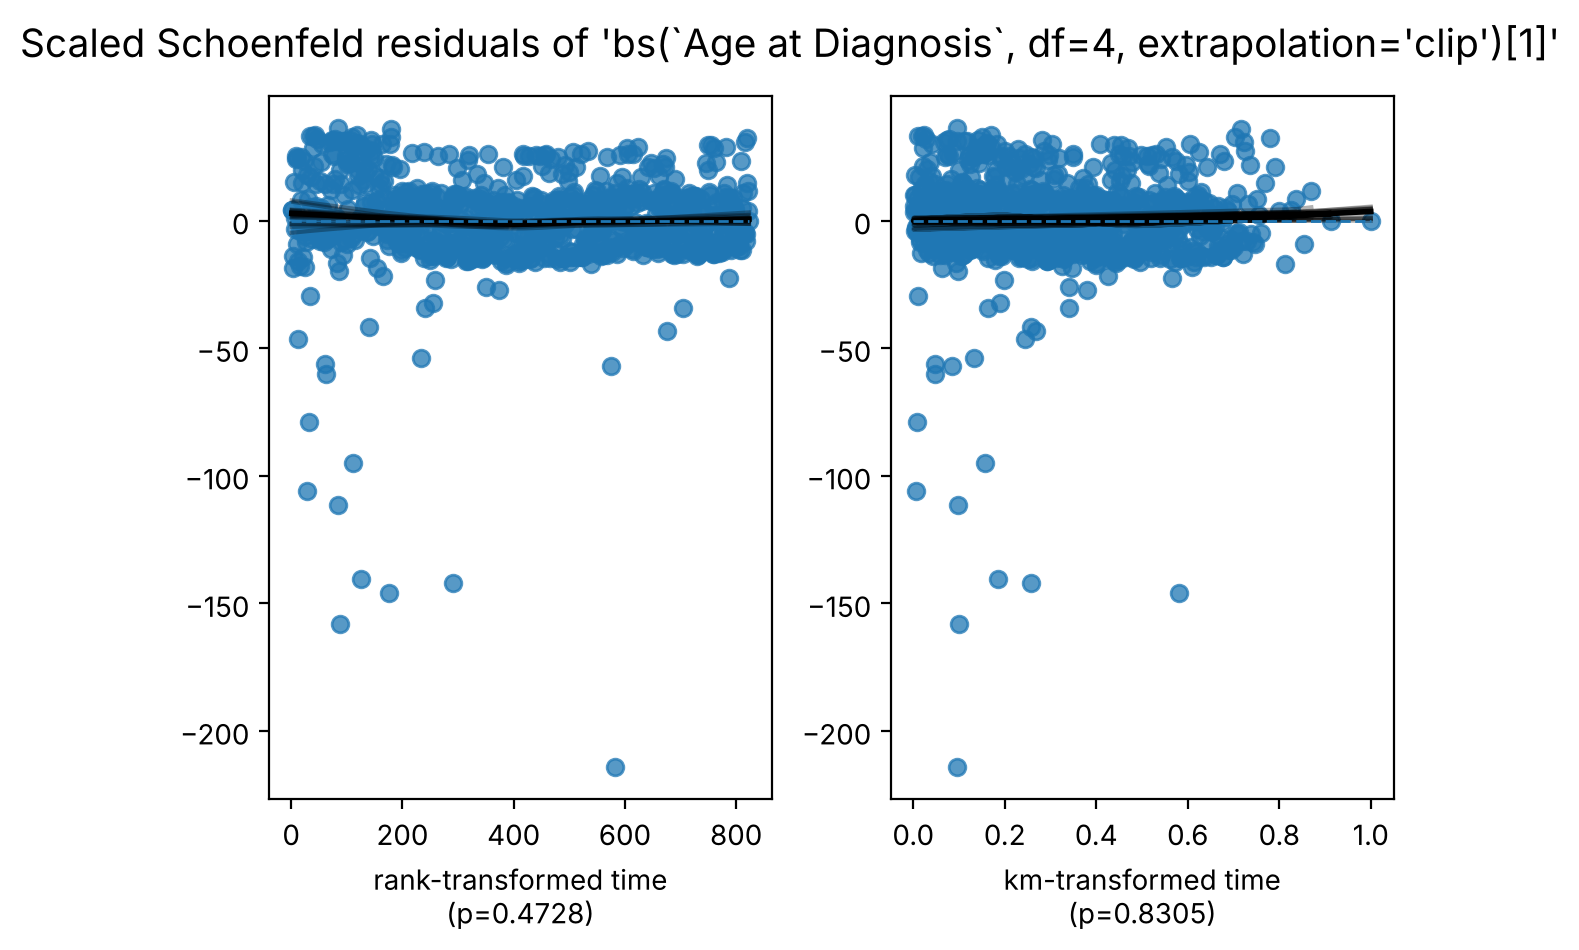

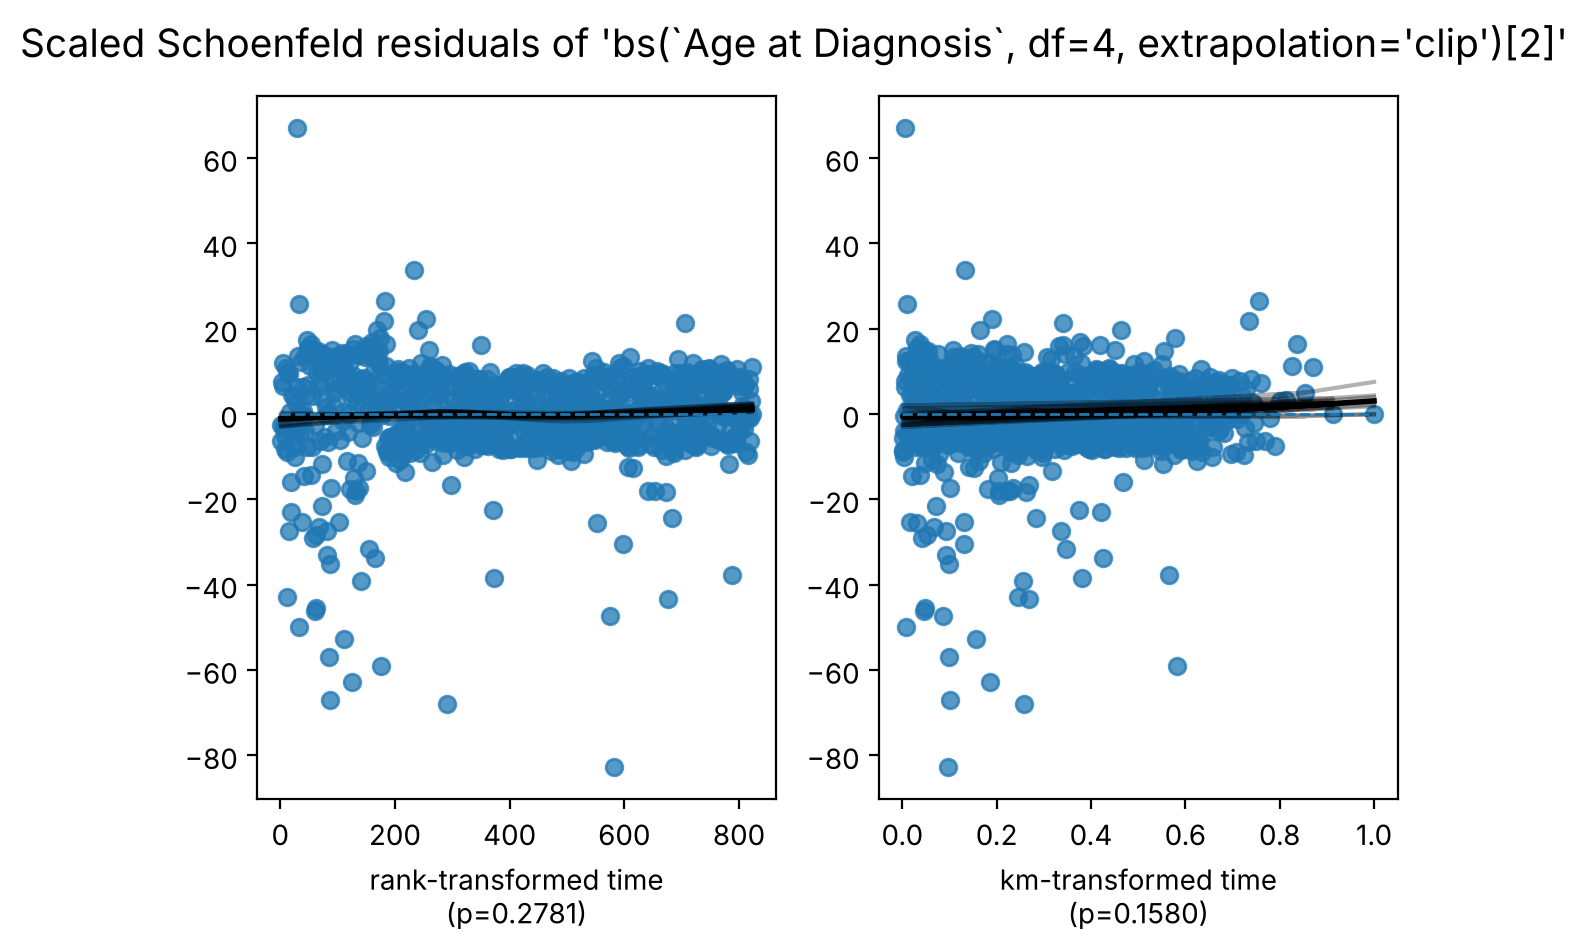

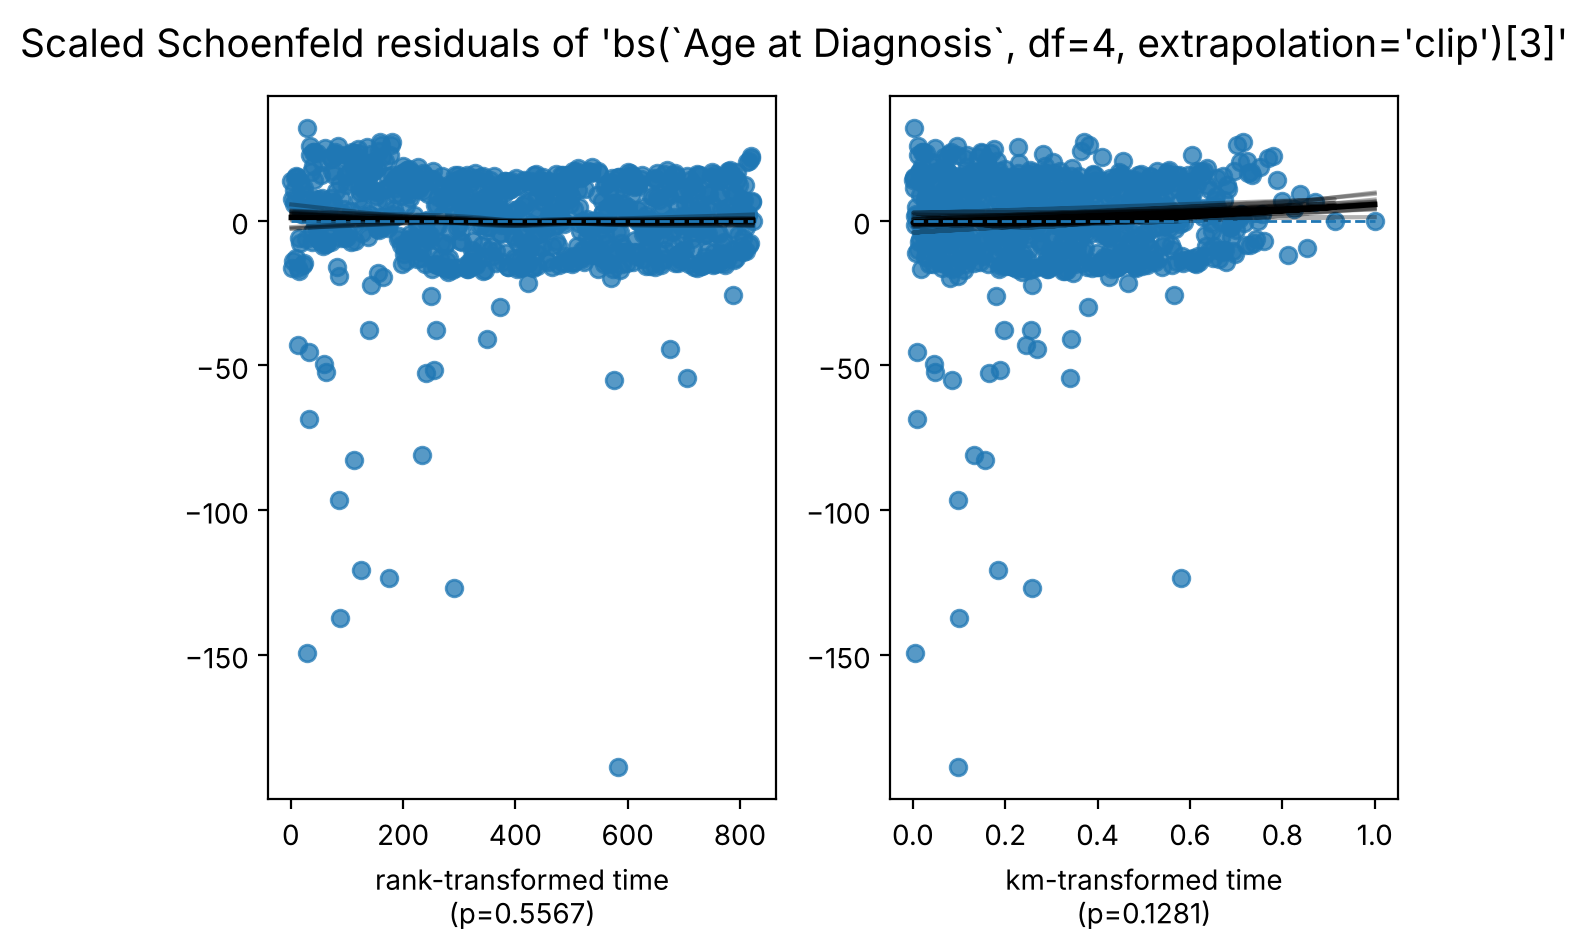

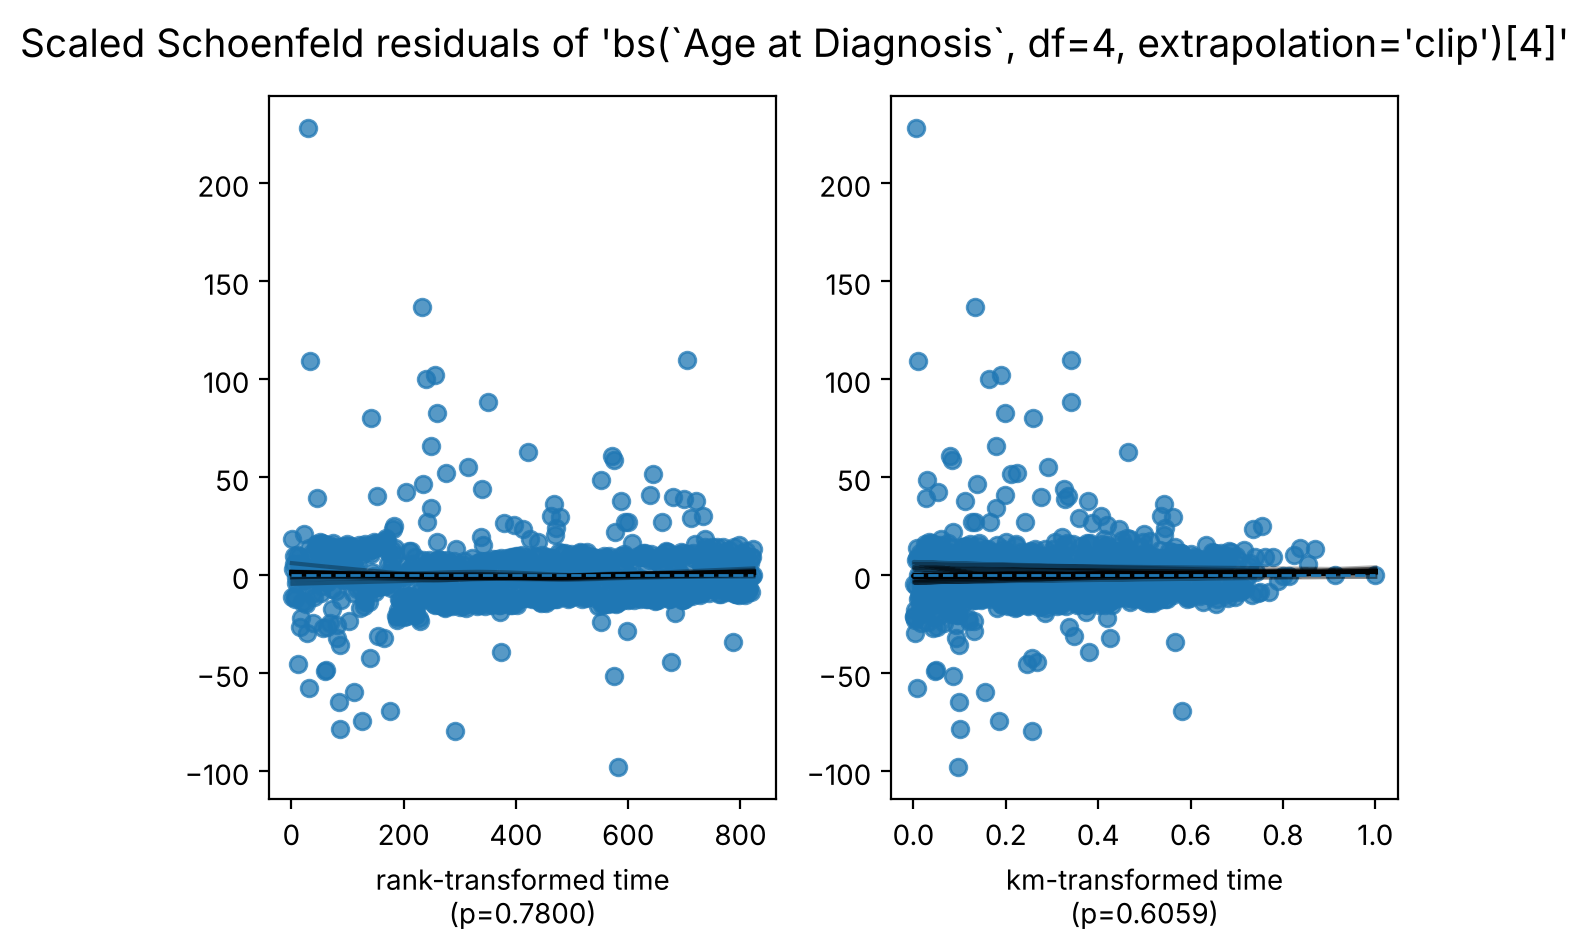

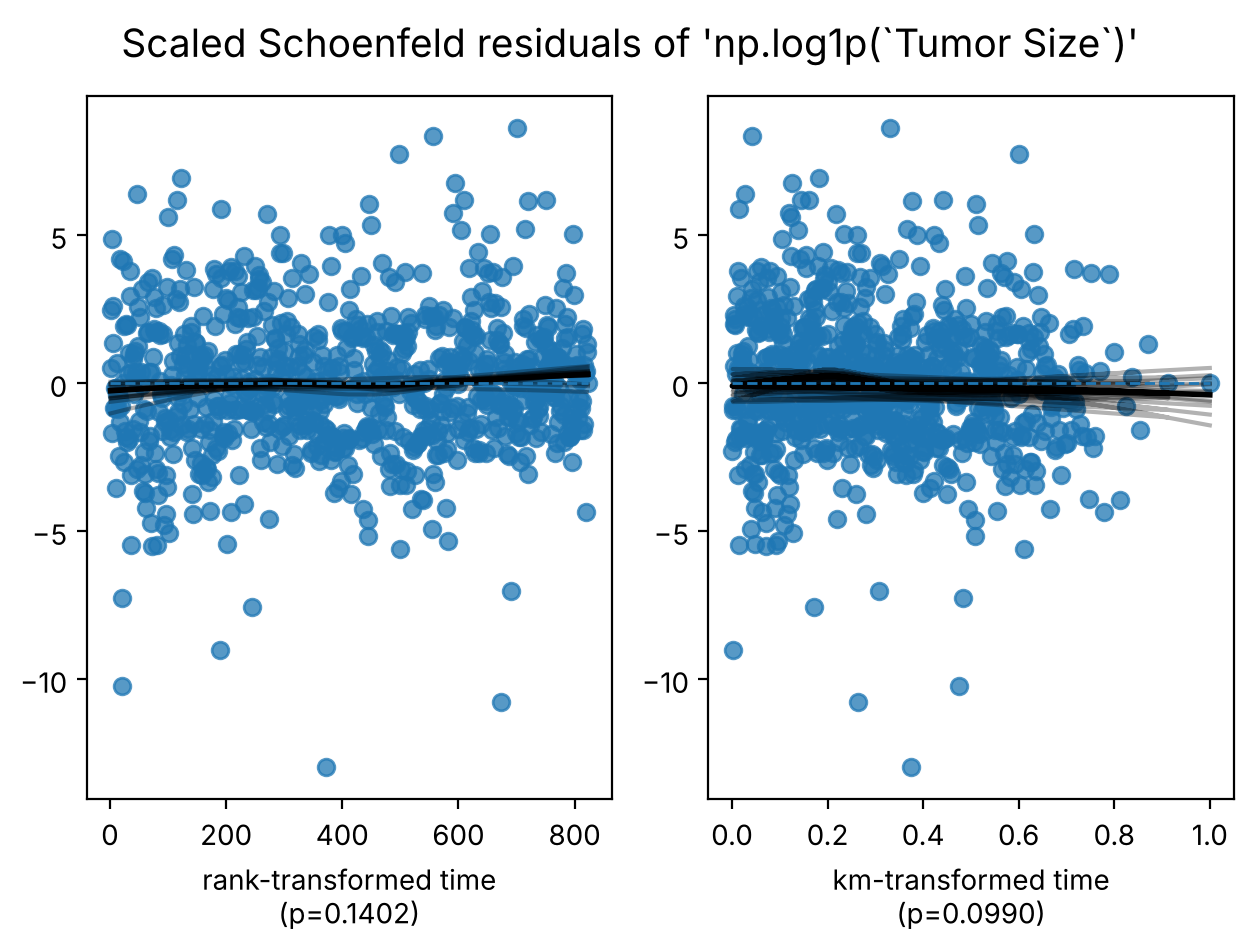

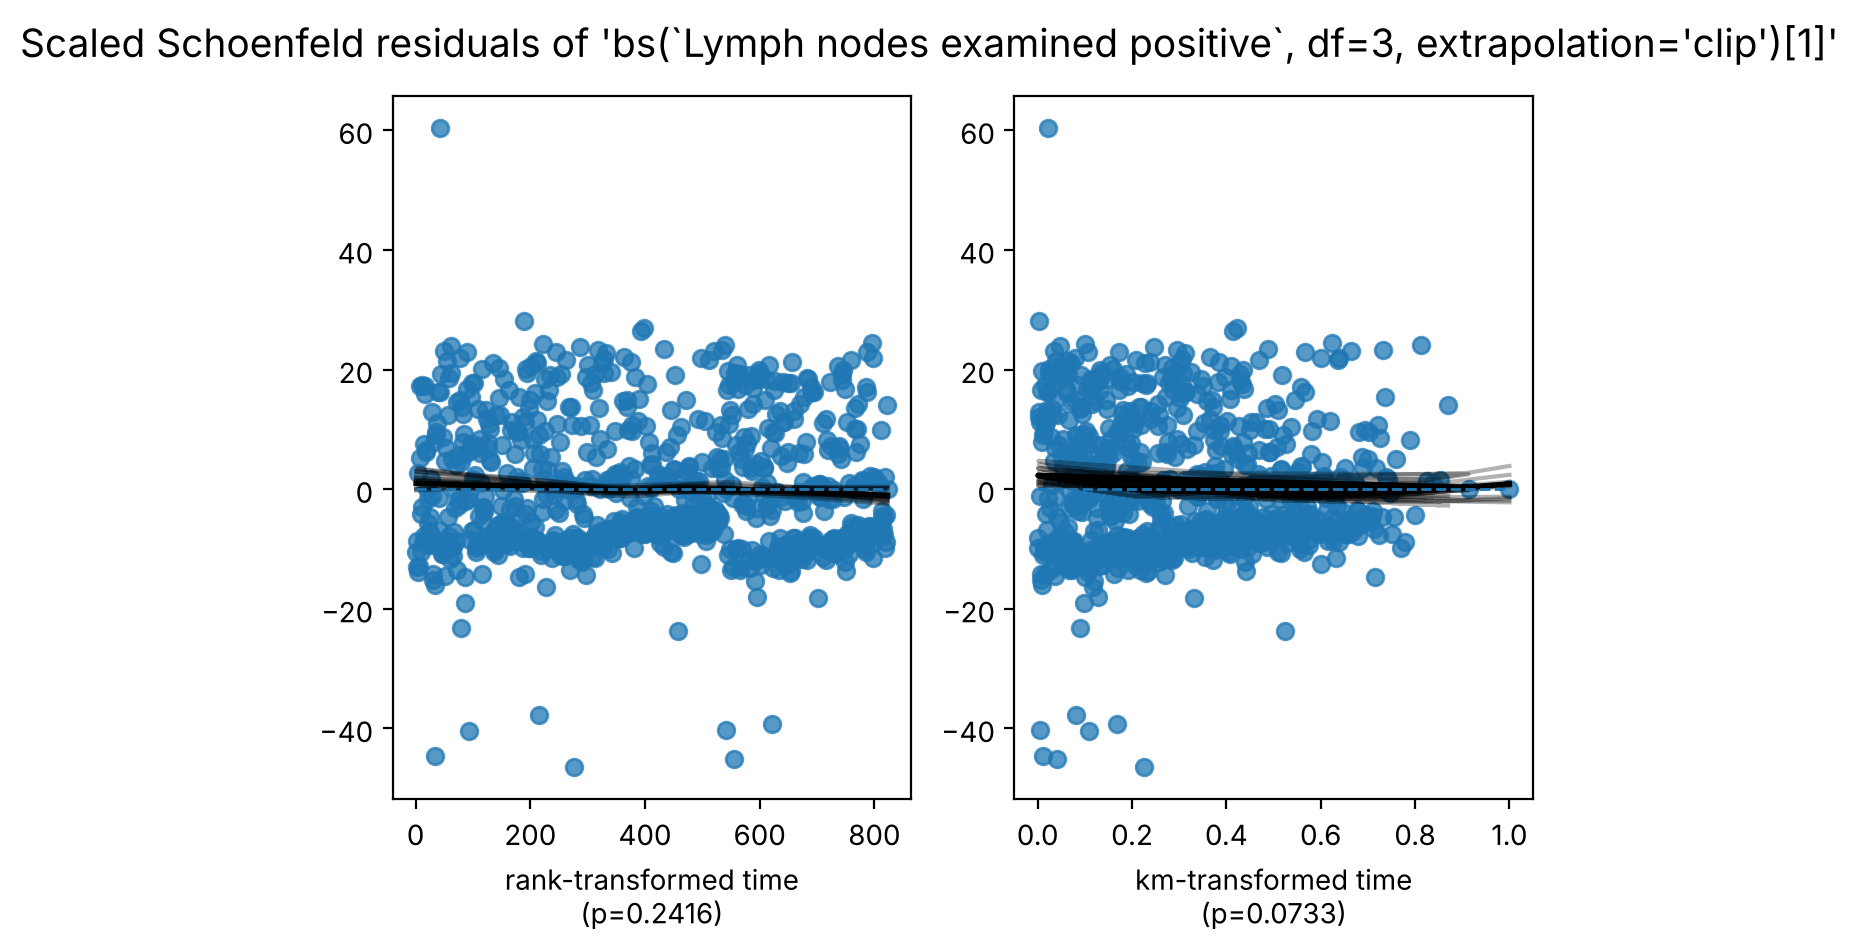

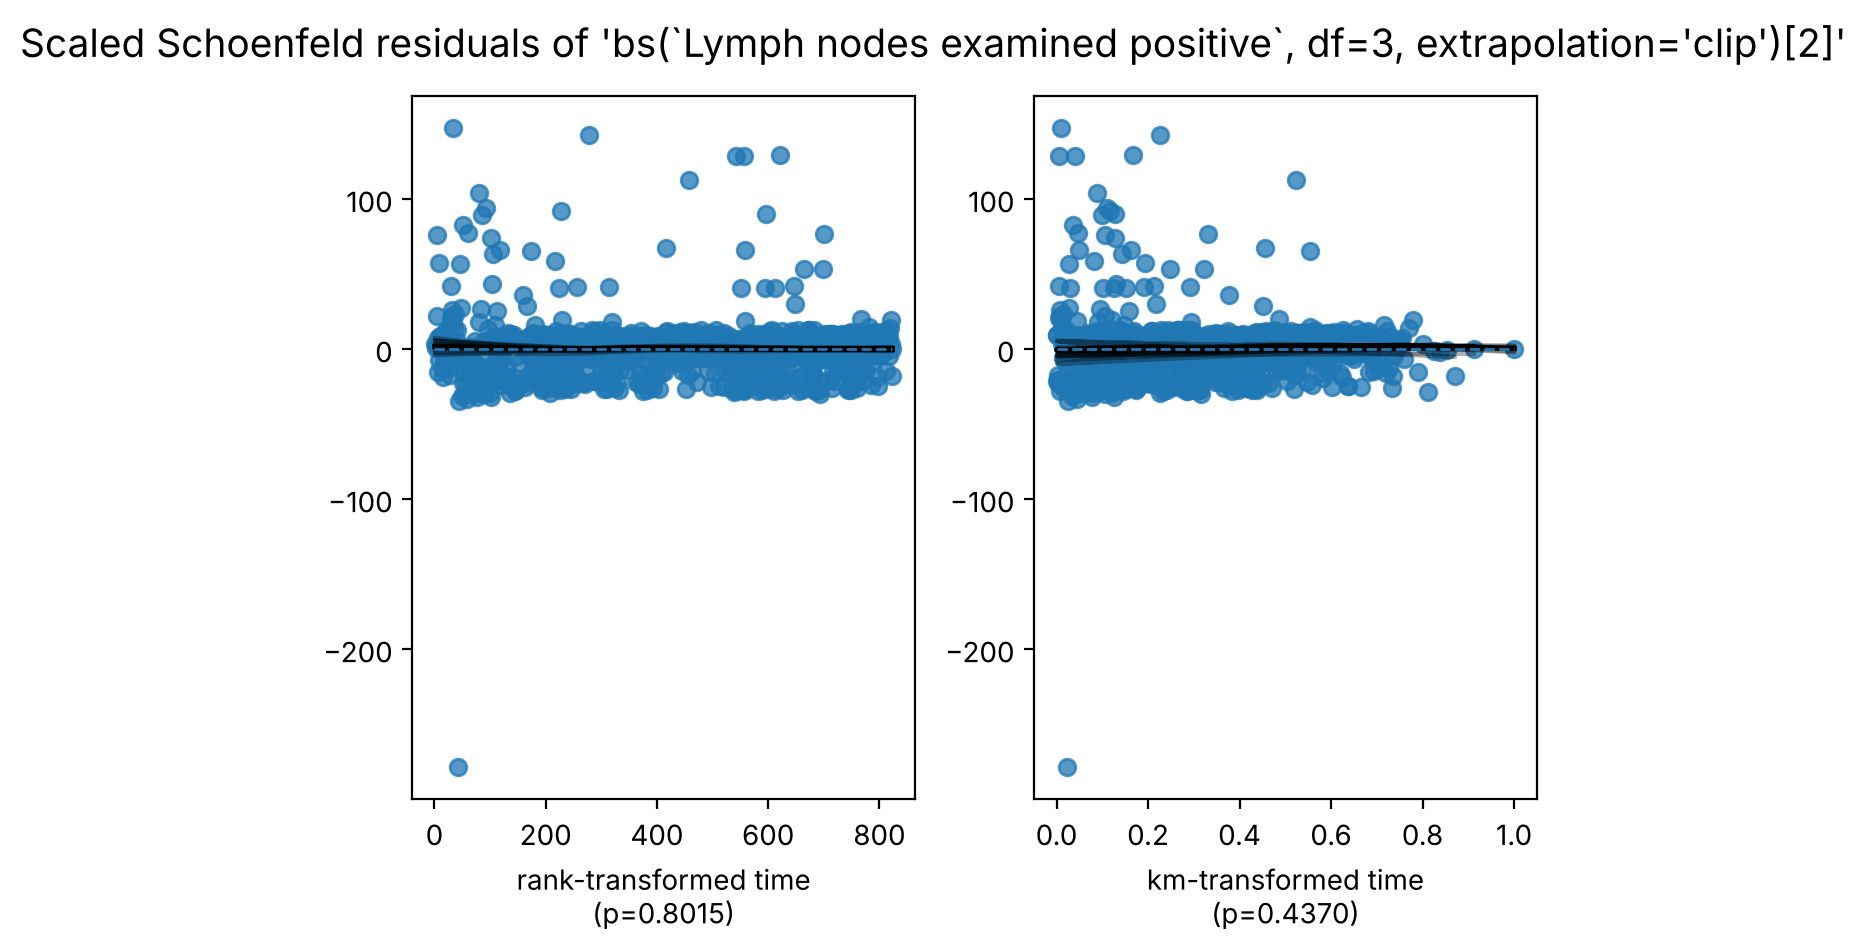

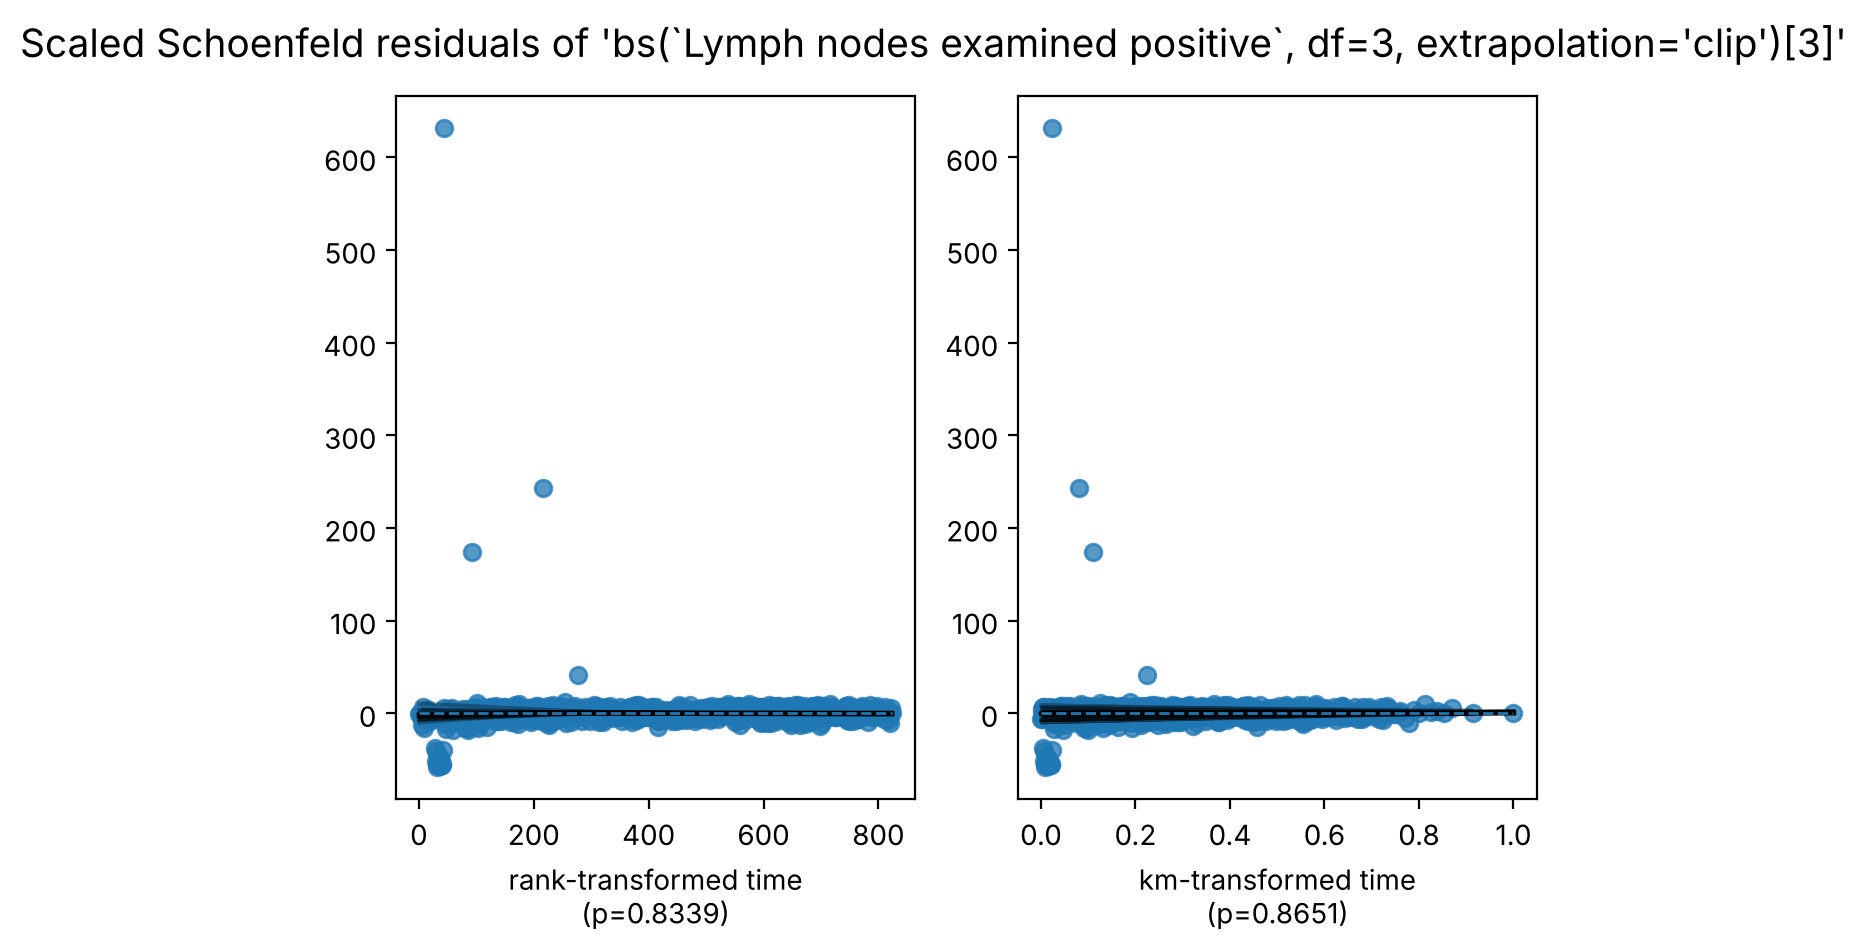

In [13]:
# Recheck proportional hazards on the final model (on the data the model was fit on)
cph.check_assumptions(train_df, p_value_threshold=0.05, show_plots=True)

> **Result**
>
> lifelines reports **"Proportional hazard assumption looks okay"**: no term fails on either time scale. The fixes worked:
>
> - **ER and grade** are now strata.
> - **Age's** violation came from forcing a straight line onto a curved effect, and the spline removes it.
> - **Size and nodes** passed from the start.

## 12. Test Set

The final model is scored **once** on the 359 test patients, who have not been used in any decision so far.

In [14]:
# Test the model once on the held-out test set
print(f"Test C-index (10-year survival): {c_index_10yr(cph, test_df):.3f}")
print(f"Test C-index (partial hazard):   {c_index_partial(cph, test_df):.3f}")

Test C-index (10-year survival): 0.674
Test C-index (partial hazard):   0.650


> **Result**
>
> | | C-index (10-year survival) | C-index (partial hazard) |
> |---|---|---|
> | Held-out test set | **0.674** | 0.650 |
>
> The test score is close to the cross-validation estimate (0.680), so the model is not overfitted: it ranks about two out of three patient pairs correctly on patients it has never seen.

## 13. How Stable Is the Test Score?

A single test score depends on which 359 patients happened to land in the test set (Debray et al., 2023). To show how much it moves, the split and final fit are repeated with 30 different random seeds.

This does **not** change the model: the recipe stays exactly the same. Picking the seed with the best test score would be cherry-picking, so seed 42 stays fixed throughout.

In [15]:
# How much does the test score depend on which patients land in the test set?
# Repeat the split and final fit with 30 different seeds (the model recipe stays the same)
seed_scores = []
for seed in range(30):
    tr, te = train_test_split(data_cols, test_size=0.2, shuffle=True,
                              random_state=seed, stratify=data_cols[surv_status])
    model = CoxPHFitter()
    model.fit(tr, duration_col=surv_time, event_col=surv_status, strata=strata_vars, formula=formula)
    seed_scores.append(c_index_10yr(model, te))
print(f"Test C-index over 30 splits: mean {np.mean(seed_scores):.3f}, "
      f"range {min(seed_scores):.3f} to {max(seed_scores):.3f}")

Test C-index over 30 splits: mean 0.683, range 0.650 to 0.713


> **Result**
>
> Across 30 random splits, the test C-index averages **0.683** and ranges from **0.650 to 0.713**. Seed 42's 0.674 is close to typical.
>
> A spread of about ±0.03 from the split alone is why the cross-validation estimate, which averages over five folds, is the main performance measure.

## 14. What the Model Says About Each Predictor

Because age and lymph nodes are splines and tumour size is on a log scale, their effects are best shown as curves. Each plot changes one predictor across its observed range (1st to 99th percentile), holds the others at the training median, and compares the risk of death to a median patient.

The median patient is 61.5 years old, with a 23 mm tumour, 0 positive nodes, ER-positive, grade 1–2. A relative risk of 1 means the same risk as that patient.

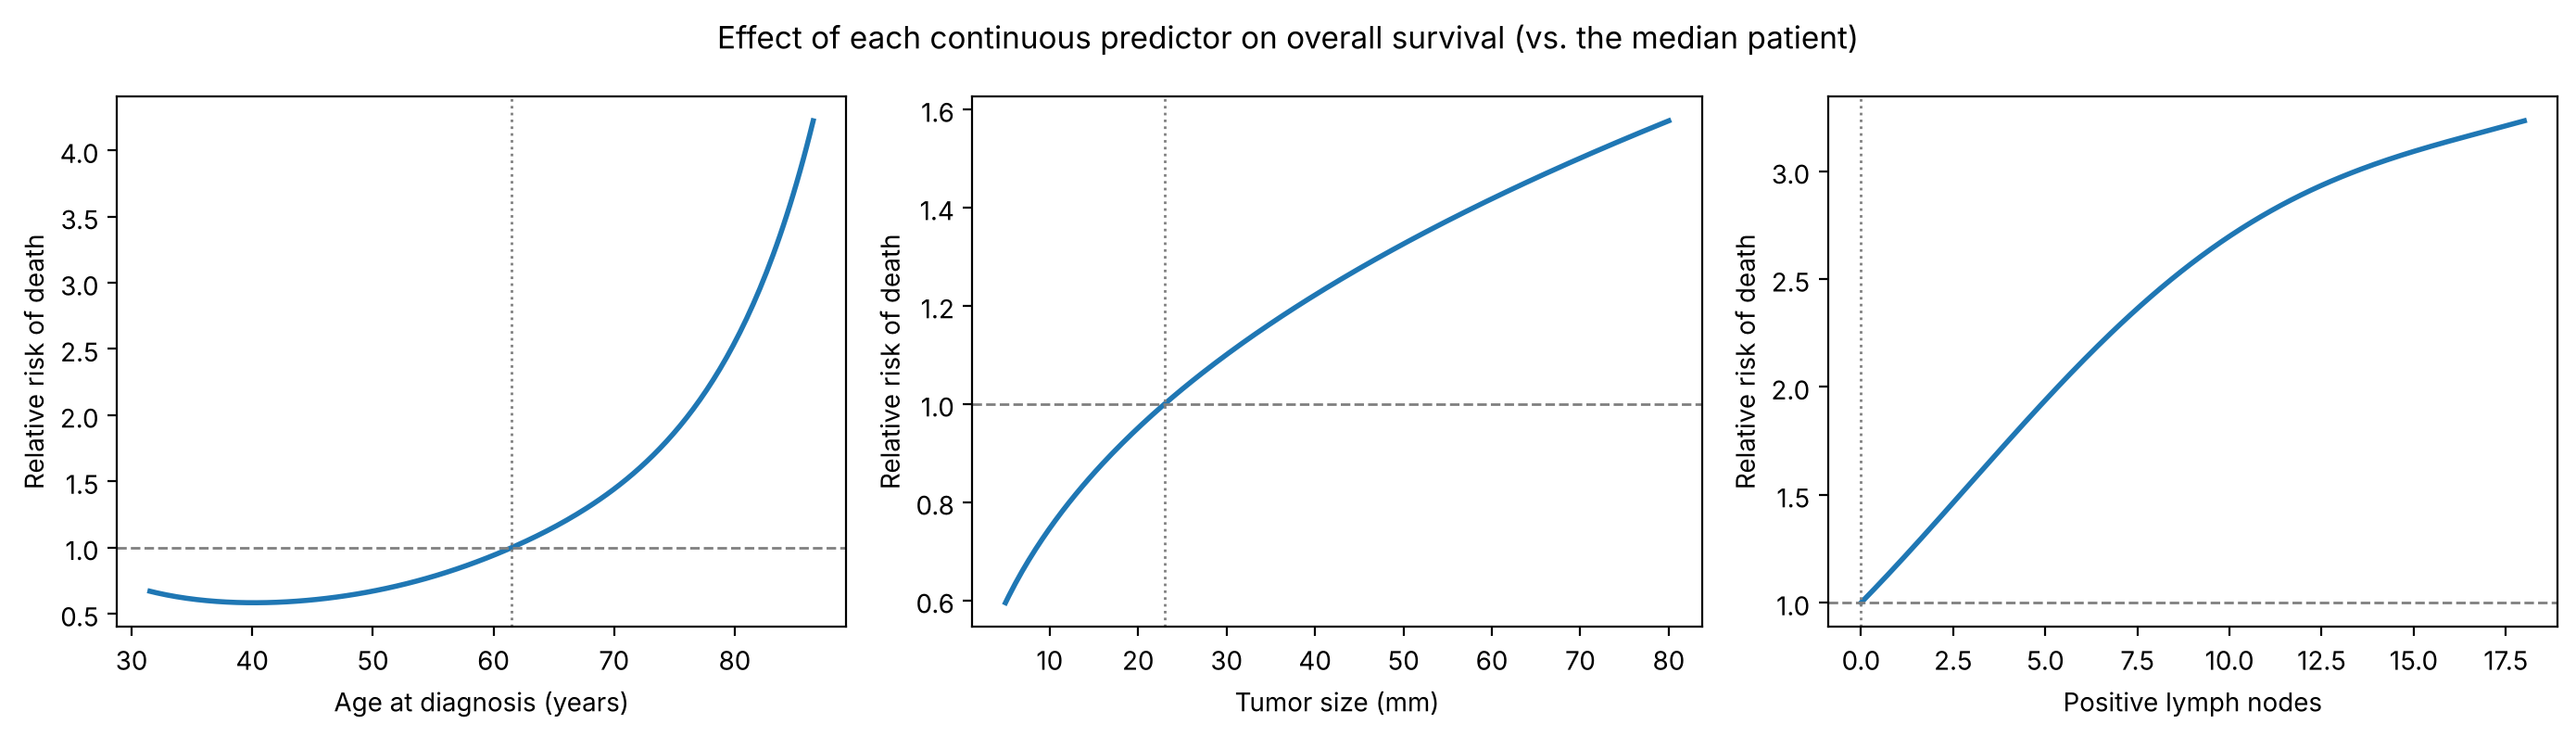

In [16]:
# Effect plots: splines and logs have no single hazard ratio, so plot each predictor's effect instead
# Change one predictor at a time, hold the others at their training median, compare to the median patient
typical = {'Age at Diagnosis': train_df['Age at Diagnosis'].median(),
           'Tumor Size': train_df['Tumor Size'].median(),
           'Lymph nodes examined positive': train_df['Lymph nodes examined positive'].median(),
           'ER status measured by IHC_Positve': 1, 'High grade (3)': 0}
reference_risk = cph.predict_partial_hazard(pd.DataFrame([typical])).values[0]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (var, label) in zip(axes, [('Age at Diagnosis', 'Age at diagnosis (years)'),
                                   ('Tumor Size', 'Tumor size (mm)'),
                                   ('Lymph nodes examined positive', 'Positive lymph nodes')]):
    grid = np.linspace(train_df[var].quantile(0.01), train_df[var].quantile(0.99), 200)
    profile = pd.DataFrame([typical] * len(grid))
    profile[var] = grid
    relative_risk = cph.predict_partial_hazard(profile).reindex(profile.index).values / reference_risk
    ax.plot(grid, relative_risk, linewidth=2)
    ax.axhline(1, linestyle='--', color='gray', linewidth=1)
    ax.axvline(typical[var], linestyle=':', color='gray', linewidth=1)
    ax.set_xlabel(label)
    ax.set_ylabel('Relative risk of death')
fig.suptitle('Effect of each continuous predictor on overall survival (vs. the median patient)')
plt.tight_layout()
plt.show()

> **Result**
>
> - **Age:** risk is lowest around age 40 and roughly flat through the 40s and 50s, then climbs steeply. Compared with the median patient, a 70-year-old has **1.44 times** the risk and an 80-year-old **2.55 times**. A straight line cannot capture that bend, which is why linear age failed in Sections 5 and 8.
> - **Tumour size:** risk rises with diminishing returns. A 10 mm tumour has **0.75 times** the median risk, a 50 mm tumour **1.33 times** and a 100 mm tumour **1.71 times**.
> - **Lymph nodes:** risk rises steeply over the first ~10 positive nodes and then levels off. 1 node gives **1.18 times** the risk, 5 nodes **1.94 times** and 10 nodes **2.70 times**.
>
> All three shapes are clinically plausible, and each matches the shape chosen by the comparisons in Section 8.

## 15. How Far Ahead Can the Model Predict?

Each stratum's baseline survival curve is estimated from the patients in that stratum who are still being followed. Far into follow-up, few patients remain and the curve becomes unreliable. The check below counts, at each time point, the patients still followed in the **smallest** stratum.

In [17]:
# How many training patients are still being followed at each time point?
# Predictions far beyond where few patients remain are unreliable
for years in [5, 10, 15, 20, 25]:
    at_risk = train_df[train_df[surv_time] >= years * 12].groupby(strata_vars).size()
    print(f"{years:>2} years: smallest stratum still followed = {at_risk.min()} patients")

 5 years: smallest stratum still followed = 32 patients
10 years: smallest stratum still followed = 21 patients
15 years: smallest stratum still followed = 12 patients
20 years: smallest stratum still followed = 4 patients
25 years: smallest stratum still followed = 1 patients


> **Result**
>
> | Years | Patients still followed in the smallest stratum |
> |---|---|
> | 5 | 32 |
> | 10 | 21 |
> | 15 | 12 |
> | 20 | 4 |
> | 25 | 1 |
>
> We set the rule that every stratum needs **at least 10 patients still followed**, the same order of magnitude as the events-per-variable guidance in Section 3. That holds up to 15 years and fails at 20, so **predictions are capped at 15 years**. The 10-year scoring horizon in Section 7 sits well inside this range.

## 16. Patient Prediction Form

Enter a patient's information at diagnosis to see her predicted overall survival: the chance of being alive at 5 and 10 years, the median survival time, and the full predicted survival curve up to 15 years.

The form passes the raw values. The model's formula applies the log and spline transforms itself, and grade is converted to 3 vs. 1–2 the same way as in training. For example, a 55-year-old with a 20 mm, grade 2, ER-positive tumour and no positive nodes has a predicted **94.0%** 5-year and **81.6%** 10-year survival.

In [18]:
# Patient Prediction Form: enter a patient's info to get their predicted survival
import ipywidgets as widgets
from IPython.display import display

# Input boxes for each variable the model was trained on
style = {'description_width': '130px'}
age_box = widgets.BoundedFloatText(value=55, min=20, max=100, description='Age (years):', style=style)
size_box = widgets.BoundedFloatText(value=20, min=1, max=200, description='Tumor size (mm):', style=style)
nodes_box = widgets.BoundedIntText(value=0, min=0, max=50, description='Positive nodes:', style=style)
grade_box = widgets.Dropdown(options=[1, 2, 3], value=2, description='Histologic grade:', style=style)
er_box = widgets.Dropdown(options=[('Positive', 1), ('Negative', 0)], value=1, description='ER status:', style=style)
button = widgets.Button(description='Predict', button_style='primary')
output = widgets.Output()

def predict(_):
    # Put the inputs into a one-row table with the same column names as the training data
    # (the model's formula applies the log and spline transforms itself)
    patient = pd.DataFrame([{
        'Age at Diagnosis': age_box.value,
        'Tumor Size': size_box.value,
        'Lymph nodes examined positive': nodes_box.value,
        'High grade (3)': 1 if grade_box.value == 3 else 0, #model groups grade into 3 vs 1-2
        'ER status measured by IHC_Positve': er_box.value
    }])

    # Predicted chance of being alive (from any cause), month by month for 15 years
    # (capped at 180 months, see the follow-up check above)
    months = np.arange(0, 181)
    surv = cph.predict_survival_function(patient, times=months).iloc[:, 0]

    # Median survival: the first month the predicted survival chance drops to 50% or below
    below_half = surv[surv <= 0.5]
    if len(below_half) > 0:
        median = f"{below_half.index[0] / 12:.1f} years"
    else:
        median = "more than 15 years"

    with output:
        output.clear_output()
        print(f"5-year survival:  {surv.loc[60]:.1%}")
        print(f"10-year survival: {surv.loc[120]:.1%}")
        print(f"Median survival:  {median}")

        # Plot the patient's predicted survival curve
        plt.figure(figsize=(6, 3.5))
        plt.step(months / 12, surv, where='post')
        plt.axhline(0.5, linestyle='--', color='gray', linewidth=1)
        plt.ylim(0, 1.02)
        plt.xlabel('Years since diagnosis')
        plt.ylabel('Probability of survival')
        plt.title('Predicted overall survival')
        plt.tight_layout()
        plt.show()

# Run predict() every time the button is clicked, then show the form
button.on_click(predict)
display(age_box, size_box, nodes_box, grade_box, er_box, button, output)

BoundedFloatText(value=55.0, description='Age (years):', min=20.0, style=DescriptionStyle(description_width='1…

BoundedFloatText(value=20.0, description='Tumor size (mm):', max=200.0, min=1.0, style=DescriptionStyle(descri…

BoundedIntText(value=0, description='Positive nodes:', max=50, style=DescriptionStyle(description_width='130px…

Dropdown(description='Histologic grade:', index=1, options=(1, 2, 3), style=DescriptionStyle(description_width…

Dropdown(description='ER status:', options=(('Positive', 1), ('Negative', 0)), style=DescriptionStyle(descript…

Button(button_style='primary', description='Predict', style=ButtonStyle())

Output()

## 17. Conclusions and Limitations

**Conclusions**

- **Performance:** a Cox model using five clinical variables known at diagnosis predicts overall survival with a cross-validated C-index of **0.680** and a held-out test C-index of **0.674**. It ranks about two out of three patient pairs correctly.
- **Assumptions:** every modelling choice was tested on the training data, and the final model satisfies the proportional hazards assumption.
- **ER and grade** affect risk differently over time, so they are modelled as strata.
- **Age, tumour size and lymph nodes** have curved effects: age matters most after 60, tumour size with diminishing returns, and nodes mostly over the first ten.

**Limitations**

- **Missing data:** complete-case analysis dropped 187 patients with an outcome but a missing predictor. Their survival did not differ, but multiple imputation could add statistical power.
- **Validation:** the test set comes from the same cohort, so this is internal validation only. External validation on a different cohort would be needed before any real use.
- **Era:** METABRIC patients were diagnosed between 1977 and 2005, and treatment has improved since, so predictions reflect that historical cohort.
- **Grade grouping:** grouping grades 1 and 2 was needed for stable strata, but it loses the difference between them.
- **Calibration:** whether predicted survival probabilities match observed survival was not assessed. Only discrimination (the C-index) was measured.
- **Predictors:** HER2 and PR status and treatment are not in the model. This is a student capstone project, not a clinical tool.

## 18. References

- Anderson WF, Chen BE, Jatoi I, Rosenberg PS (2006). Effects of estrogen receptor expression and histopathology on annual hazard rates of death from breast cancer. *Breast Cancer Research and Treatment*, 100, 121–126. doi:10.1007/s10549-006-9231-y
- Cerami E, et al. (2012). The cBio cancer genomics portal. *Cancer Discovery*, 2(5), 401–404.
- Collins GS, Reitsma JB, Altman DG, Moons KGM (2015). Transparent reporting of a multivariable prediction model for individual prognosis or diagnosis (TRIPOD): the TRIPOD Statement. *BMC Medicine*, 13, 1. doi:10.1186/s12916-014-0241-z
- Collins GS, Ogundimu EO, Cook JA, Le Manach Y, Altman DG (2016). Quantifying the impact of different approaches for handling continuous predictors on the performance of a prognostic model. *Statistics in Medicine*, 35(23), 4124–4135. doi:10.1002/sim.6986
- Curtis C, et al. (2012). The genomic and transcriptomic architecture of 2,000 breast tumours reveals novel subgroups. *Nature*, 486, 346–352.
- Debray TPA, Collins GS, Riley RD, Snell KIE, Van Calster B, Reitsma JB, Moons KGM (2023). Transparent reporting of multivariable prediction models developed or validated using clustered data (TRIPOD-Cluster): explanation and elaboration. *BMJ*, 380, e071058. doi:10.1136/bmj-2022-071058
- Frontiers in Oncology (2024). Time-varying effect in older patients with early-stage breast cancer: a model considering the competing risks based on a time scale. doi:10.3389/fonc.2024.1352111
- Gao J, et al. (2013). Integrative analysis of complex cancer genomics and clinical profiles using the cBioPortal. *Science Signaling*, 6(269), pl1.
- Grambsch PM, Therneau TM (1994). Proportional hazards tests and diagnostics based on weighted residuals. *Biometrika*, 81(3), 515–526. doi:10.1093/biomet/81.3.515
- Harrell FE, Lee KL, Mark DB (1996). Multivariable prognostic models: issues in developing models, evaluating assumptions and adequacy, and measuring and reducing errors. *Statistics in Medicine*, 15(4), 361–387.
- Hughes RA, Heron J, Sterne JAC, Tilling K (2019). Accounting for missing data in statistical analyses: multiple imputation is not always the answer. *International Journal of Epidemiology*. doi:10.1093/ije/dyz032
- Mukherjee A, et al. (2018). Associations between genomic stratification of breast cancer and centrally reviewed tumour pathology in the METABRIC cohort. *NPJ Breast Cancer*, 4, 5. doi:10.1038/s41523-018-0056-8
- Peduzzi P, Concato J, Feinstein AR, Holford TR (1995). Importance of events per independent variable in proportional hazards regression analysis. II. Accuracy and precision of regression estimates. *Journal of Clinical Epidemiology*, 48(12), 1503–1510.
- Rakha EA, et al. (2010). Breast cancer prognostic classification in the molecular era: the role of histological grade. *Breast Cancer Research*, 12, 207. doi:10.1186/bcr2607
- Sarfati D, Blakely T, Pearce N (2010). Measuring cancer survival in populations: relative survival vs cancer-specific survival. *International Journal of Epidemiology*, 39(2), 598.
- Sierra BB, McLean C, Hall PS, Vallejos CA (2025). The C-index Multiverse. *arXiv*:2508.14821.
- Sun GW, Shook TL, Kay GL (1996). Inappropriate use of bivariable analysis to screen risk factors for use in multivariable analysis. *Journal of Clinical Epidemiology*, 49(8), 907–916.
- Therneau TM, Grambsch PM (2000). *Modeling Survival Data: Extending the Cox Model*. Springer.